# A3 — Classificador com CNN Pré-treinada (Transfer Learning)

**Disciplina:** Visão Computacional com CNNs e Transformers

**Requisitos de execução**
- **GPU:** Colab T4 (Runtime > Change runtime type > T4 GPU). Também roda em CPU, bem mais devagar.
- **Memória:** ~4 GB de RAM e ~2 GB de disco (zip de ~1 GB + imagens extraídas).
- **Tempo estimado:** ~5 a 8 minutos (download do dataset + 10 épocas de treino).
- **Pré-requisito:** montar o Google Drive e disponibilizar o dataset (secret `KAGGLE_API_TOKEN` no Colab ou o `.zip` na pasta do projeto; ver a seção de download).
- **Dataset:** [Images Dataset](https://www.kaggle.com/datasets/pavansanagapati/images-dataset) (Pavan Sanagapati), com 1.803 imagens em 7 categorias: bike, cars, cats, dogs, flowers, horses e human.

## Roadmap

1. Ambiente (seed, device, versões)
2. Download e carregamento do dataset
3. Análise exploratória
4. Divisão treino/validação/teste e pré-processamento
5. Transfer learning por feature extraction (ResNet-50 pré-treinada)
6. Treinamento, resultados e análise de erros
7. Checkpoint e requirements.txt
8. Discussão: feature extraction vs. fine-tuning e propostas de augmentation

## Ambiente

In [24]:
import random

SEED = 42
random.seed(SEED)

import numpy as np
np.random.seed(SEED)

import torch
torch.manual_seed(SEED)

print(f"Seed configurada: {SEED}")

Seed configurada: 42


In [25]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

if device.type == "cpu":
    print(
        "Aviso: rodando em CPU. Em Runtime > Change runtime type, "
        "selecione GPU (T4) para acelerar o treinamento."
    )

Device: cuda


In [26]:
import pandas as pd
import sklearn
import torchvision

print(f"PyTorch: {torch.__version__}")
print(f"Torchvision: {torchvision.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1


## Download e Carregamento do Dataset

O dataset é baixado pela API do Kaggle. Para isso, adicione nos *Secrets* do Colab (ícone de chave na barra lateral) um segredo chamado `KAGGLE_API_TOKEN` com o token da sua conta Kaggle e ative *Notebook access*.

Alternativa sem token: baixe o `.zip` em https://www.kaggle.com/datasets/pavansanagapati/images-dataset e coloque-o na pasta `PROJECT_DIR` do Google Drive. A célula de download o extrai automaticamente.

In [27]:
import os
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/3_cnn"
os.makedirs(PROJECT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
import glob
import subprocess
import sys
import zipfile

DATA_DIR = "/content/a3_data"

try:
    from google.colab import userdata

    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "kaggle"], check=True)
    subprocess.run(
        ["kaggle", "datasets", "download", "-d", "pavansanagapati/images-dataset", "-p", DATA_DIR, "--unzip"],
        check=True,
    )
except Exception:
    zip_files = glob.glob(f"{PROJECT_DIR}/*.zip")
    assert zip_files, "Configure o secret KAGGLE_API_TOKEN ou coloque o .zip do dataset em PROJECT_DIR."
    with zipfile.ZipFile(zip_files[0]) as z:
        z.extractall(DATA_DIR)

print("Dataset pronto em:", DATA_DIR)

Dataset pronto em: /content/a3_data


In [29]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")


def find_dataset_root(base_dir):
    for root, dirs, files in os.walk(base_dir):
        subdirs_with_images = [
            d for d in dirs
            if any(
                f.lower().endswith(IMAGE_EXTENSIONS)
                for f in os.listdir(os.path.join(root, d))
            )
        ]
        if len(subdirs_with_images) >= 2:
            return root
    return None


DATA_ROOT = find_dataset_root(DATA_DIR)
assert DATA_ROOT is not None, "Não encontrei as pastas de categoria."

print(f"DATA_ROOT: {DATA_ROOT}")
print("Categorias encontradas:", sorted(os.listdir(DATA_ROOT)))

DATA_ROOT: /content/a3_data/data
Categorias encontradas: ['bike', 'cars', 'cats', 'data', 'dogs', 'flowers', 'horses', 'human']


In [30]:
CATEGORIES = sorted(
    d for d in os.listdir(DATA_ROOT)
    if os.path.isdir(os.path.join(DATA_ROOT, d))
    and any(
        f.lower().endswith(IMAGE_EXTENSIONS)
        for f in os.listdir(os.path.join(DATA_ROOT, d))
    )
)

image_paths = []
image_labels = []

for category in CATEGORIES:
    category_dir = os.path.join(DATA_ROOT, category)
    for fname in os.listdir(category_dir):
        if fname.lower().endswith(IMAGE_EXTENSIONS):
            image_paths.append(os.path.join(category_dir, fname))
            image_labels.append(category)

print(f"Total de imagens: {len(image_paths)}")
print(f"Categorias ({len(CATEGORIES)}): {CATEGORIES}")

Total de imagens: 1803
Categorias (7): ['bike', 'cars', 'cats', 'dogs', 'flowers', 'horses', 'human']


## Análise Exploratória

In [31]:
import pandas as pd

df = pd.DataFrame({"path": image_paths, "label": image_labels})

print(df["label"].value_counts())
print()
print(f"Total: {len(df)} imagens")

label
cars       420
bike       365
flowers    210
cats       202
dogs       202
horses     202
human      202
Name: count, dtype: int64

Total: 1803 imagens


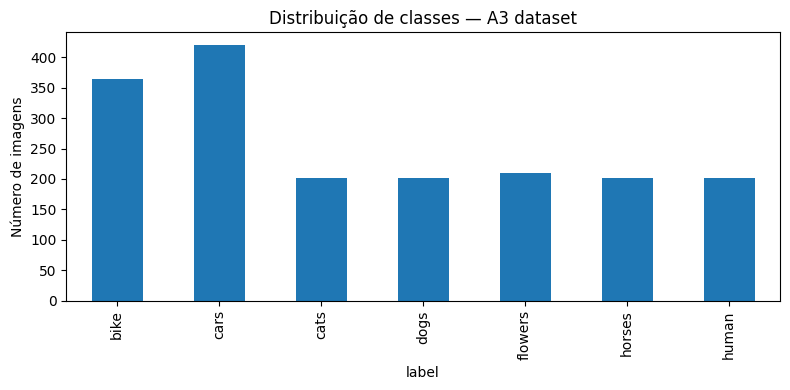

In [32]:
import matplotlib.pyplot as plt

df["label"].value_counts().sort_index().plot(kind="bar", figsize=(8, 4))
plt.ylabel("Número de imagens")
plt.title("Distribuição de classes — A3 dataset")
plt.tight_layout()
plt.show()

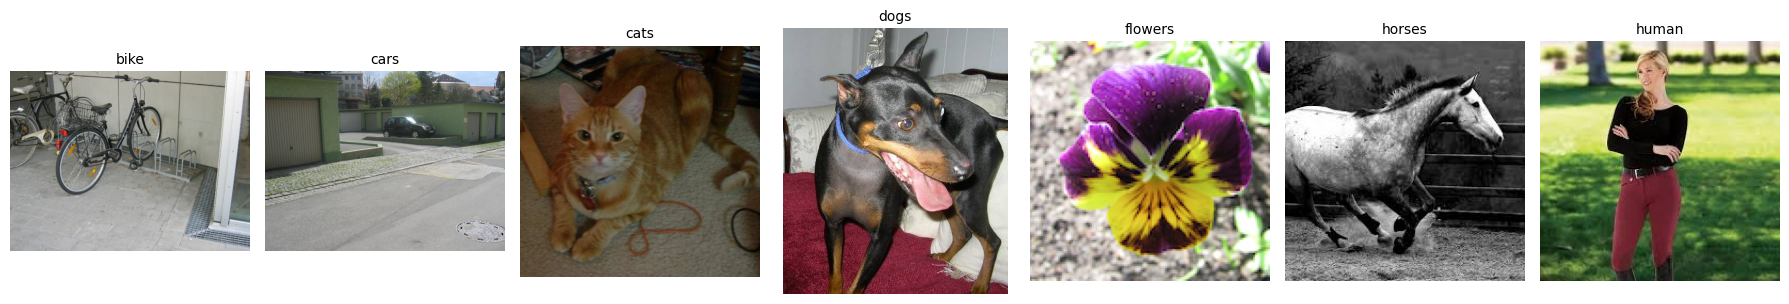

In [33]:
from PIL import Image

fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(18, 3))

for i, category in enumerate(CATEGORIES):
    sample_path = df[df["label"] == category]["path"].iloc[0]
    img = Image.open(sample_path).convert("RGB")
    axes[i].imshow(img)
    axes[i].set_title(category, fontsize=10)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

### Conclusões da análise exploratória

- O dataset tem 1.803 imagens em 7 categorias, com desbalanceamento moderado: cars (420 imagens, 23,3%) e bike (365, 20,2%) somam 43,5% do total, enquanto as outras cinco classes têm entre 202 e 210 imagens (11 a 12% cada). A razão entre a maior e a menor classe é de cerca de 2,1:1, longe de um desbalanceamento severo, por isso não foi necessário usar class weights.
- Por causa dessa diferença, a divisão é estratificada (70/15/15), preservando as proporções de classe em treino (1.262), validação (270) e teste (271), e as métricas são reportadas por classe e em média macro, não só como accuracy global.
- O suporte por classe no teste vai de 30 imagens (cats, dogs, horses) a 63 (cars). Com classes tão pequenas, cada erro custa cerca de 3,3 pontos percentuais de recall naquela classe, então as métricas por classe são sensíveis a poucos exemplos.
- A maioria das categorias (cavalos, carros, cães, gatos, bicicletas) tem classes diretamente relacionadas no ImageNet; flores têm classes parciais e pessoas não têm uma classe própria, mas aparecem com frequência nas imagens do ImageNet. Isso antecipa que a extração de features deve funcionar bem aqui.

## Divisão em Treino, Validação e Teste

Split estratificado 70/15/15, preservando a proporção de classes em cada conjunto.

In [34]:
from sklearn.model_selection import train_test_split

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    df["path"].tolist(),
    df["label"].tolist(),
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"].tolist()
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

print(f"Treino: {len(train_paths)}")
print(f"Validação: {len(val_paths)}")
print(f"Teste: {len(test_paths)}")

Treino: 1262
Validação: 270
Teste: 271


## Pré-processamento

**Normalização obrigatória (não opcional):** como o backbone ResNet-50 foi
pré-treinado no ImageNet, as imagens devem ser normalizadas com a mesma
média e desvio padrão usados naquele pré-treinamento
(`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`) — usar
estatísticas diferentes (ou nenhuma normalização) desalinha a distribuição
de entrada da distribuição que os pesos pré-treinados esperam, degradando
a qualidade das features extraídas desde a primeira camada.

Resize para 224×224 (tamanho de entrada padrão da ResNet-50 no ImageNet).


In [35]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

label_to_idx = {label: idx for idx, label in enumerate(CATEGORIES)}
idx_to_label = {idx: label for label, idx in label_to_idx.items()}

base_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class ImageFolderDataset(Dataset):

    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        image = self.transform(image)
        label = label_to_idx[self.labels[idx]]
        return image, label

train_dataset = ImageFolderDataset(train_paths, train_labels, base_transform)
val_dataset = ImageFolderDataset(val_paths, val_labels, base_transform)
test_dataset = ImageFolderDataset(test_paths, test_labels, base_transform)

BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Batches — treino: {len(train_loader)}, validação: {len(val_loader)}, teste: {len(test_loader)}")

Batches — treino: 40, validação: 9, teste: 9


## Transfer Learning — Feature Extraction (ResNet-50)

**Por que ResNet-50:** o dataset é pequeno (1.803 imagens, de 202 a 420 por classe) e tem apenas 7 classes genéricas (cavalos, carros, cães, flores, bicicletas, gatos e pessoas), todas próximas de conteúdo visto no ImageNet, onde a ResNet-50 foi pré-treinada. As features aprendidas já são diretamente aproveitáveis, e basta treinar um classificador linear sobre os 2.048 valores que o backbone produz por imagem.

**Capacidade do Colab T4 (16 GB):** com o backbone congelado, o custo se resume ao forward pass. A ResNet-50 (23,5 milhões de parâmetros) cabe com folga com batch_size=32, e o treino de 10 épocas é curto. Com 7 classes, uma EfficientNet-B0 (cerca de 5,3 milhões de parâmetros, vetor de 1.280 valores) também seria suficiente e mais leve. Optamos pela ResNet-50 por produzir uma representação maior (2.048 valores) sem custo proibitivo na T4 e por ser uma arquitetura estável e bem estabelecida para feature extraction. Uma rede maior (ex.: ResNet-101) não se justificaria para um dataset deste tamanho.

**Feature extraction (não fine-tuning):** apenas o novo classification head, `Linear(2048 → 7)` com 14.343 parâmetros, é treinado. Todo o backbone permanece congelado. A comparação com fine-tuning está na seção de discussão ao final.

In [36]:
from torchvision import models

def build_model(num_classes):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

    for param in model.parameters():
        param.requires_grad = False

    in_features = model.fc.in_features
    model.fc = torch.nn.Linear(in_features, num_classes)

    return model

model = build_model(num_classes=len(CATEGORIES)).to(device)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Parâmetros treináveis: {trainable_params:,} de {total_params:,} totais "
      f"({100 * trainable_params / total_params:.2f}%)")

Parâmetros treináveis: 14,343 de 23,522,375 totais (0.06%)


## Training Loop

In [37]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


def train_one_epoch(model, dataloader, loss_fn, optimizer, device):
    model.train()
    total_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        logits = model(X_batch)
        loss = loss_fn(logits, y_batch)
        loss.backward()
        optimizer.step()

        batch_size = X_batch.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    return total_loss / total_samples


def evaluate(model, dataloader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)

            batch_size = X_batch.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

            predictions = torch.argmax(logits, dim=1)
            all_predictions.extend(predictions.cpu().numpy())
            all_targets.extend(y_batch.cpu().numpy())

    accuracy = accuracy_score(all_targets, all_predictions)
    precision = precision_score(all_targets, all_predictions, average="macro", zero_division=0)
    recall = recall_score(all_targets, all_predictions, average="macro", zero_division=0)
    f1 = f1_score(all_targets, all_predictions, average="macro", zero_division=0)

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "predictions": all_predictions,
        "targets": all_targets
    }


def train_model(model, train_loader, val_loader, loss_fn, optimizer, device, epochs=10):
    history = {"train_loss": [], "val_loss": [], "val_accuracy": [], "val_f1": []}
    best_val_loss = float("inf")
    best_state = None

    for epoch in range(epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer, device)
        val_metrics = evaluate(model, val_loader, loss_fn, device)
        val_loss = val_metrics["loss"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_f1"].append(val_metrics["f1"])

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        print(f"Epoch [{epoch+1:02d}/{epochs}] Train Loss: {train_loss:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_metrics['accuracy']:.4f} | "
              f"Val F1: {val_metrics['f1']:.4f}")

    return history, best_state

In [38]:
loss_fn = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

history, best_state = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    device=device,
    epochs=10
)

Epoch [01/10] Train Loss: 0.8147 | Val Loss: 0.2822 | Val Acc: 0.9704 | Val F1: 0.9643
Epoch [02/10] Train Loss: 0.1798 | Val Loss: 0.1417 | Val Acc: 0.9667 | Val F1: 0.9599
Epoch [03/10] Train Loss: 0.0996 | Val Loss: 0.1070 | Val Acc: 0.9815 | Val F1: 0.9765
Epoch [04/10] Train Loss: 0.0707 | Val Loss: 0.0878 | Val Acc: 0.9852 | Val F1: 0.9812
Epoch [05/10] Train Loss: 0.0528 | Val Loss: 0.0758 | Val Acc: 0.9815 | Val F1: 0.9765
Epoch [06/10] Train Loss: 0.0384 | Val Loss: 0.0674 | Val Acc: 0.9852 | Val F1: 0.9812
Epoch [07/10] Train Loss: 0.0351 | Val Loss: 0.0599 | Val Acc: 0.9852 | Val F1: 0.9812
Epoch [08/10] Train Loss: 0.0279 | Val Loss: 0.0552 | Val Acc: 0.9852 | Val F1: 0.9812
Epoch [09/10] Train Loss: 0.0225 | Val Loss: 0.0533 | Val Acc: 0.9852 | Val F1: 0.9812
Epoch [10/10] Train Loss: 0.0193 | Val Loss: 0.0530 | Val Acc: 0.9852 | Val F1: 0.9812


## Resultados

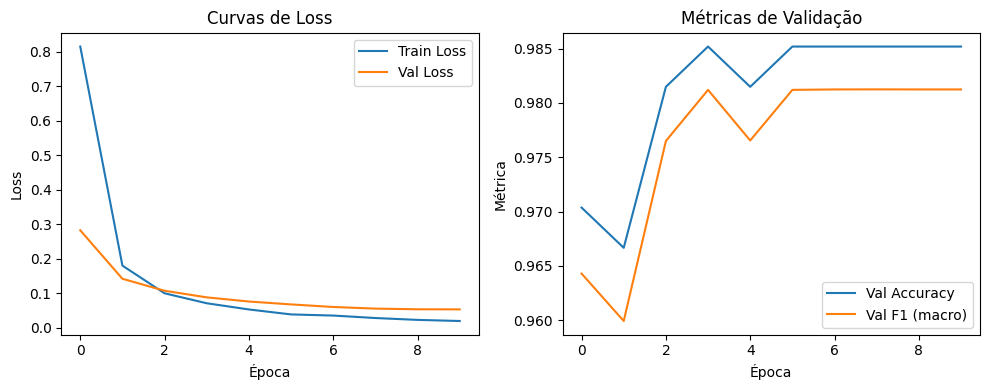

In [39]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Curvas de Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history["val_accuracy"], label="Val Accuracy")
plt.plot(history["val_f1"], label="Val F1 (macro)")
plt.xlabel("Época")
plt.ylabel("Métrica")
plt.title("Métricas de Validação")
plt.legend()

plt.tight_layout()
plt.show()

### Interpretação das curvas de treinamento

O treinamento convergiu de forma estável, sem overfitting. A Val Accuracy já era 0,9704 na época 1, o que mostra que as features pré-treinadas do ImageNet são diretamente aproveitáveis aqui, e chegou a 0,9852 (266 de 270 imagens) na época 4, mantendo-se nesse valor, com uma única oscilação para 0,9815 na época 5, até a época 10. A Val Loss caiu de forma monotônica de 0,2822 para 0,0530, com ganhos marginais nas últimas épocas (0,0552 → 0,0533 → 0,0530), o que indica convergência. O checkpoint selecionado, por menor Val Loss, é o da época 10.

A diferença entre Val Loss e Train Loss cresce suavemente (cerca de 0,02 na época 4 e 0,034 na época 10) e permanece pequena, sem a inversão típica de overfitting, em que a Train Loss cai enquanto a Val Loss sobe. Isso é esperado, já que apenas 14.343 parâmetros (0,06% do modelo) são treinados. Na época 1, a Train Loss (0,8147) é maior que a Val Loss (0,2822) porque ela é a média ao longo da época, enquanto a camada nova ainda é ajustada a partir de pesos aleatórios; a validação é medida só ao final da época.

In [40]:
model.load_state_dict(best_state)

test_metrics = evaluate(model, test_loader, loss_fn, device)

print("===== RESULTADO FINAL NO TESTE =====")
print(f"Loss: {test_metrics['loss']:.4f}")
print(f"Accuracy global: {test_metrics['accuracy']:.4f}")
print(f"Precision (macro): {test_metrics['precision']:.4f}")
print(f"Recall (macro): {test_metrics['recall']:.4f}")
print(f"F1 (macro): {test_metrics['f1']:.4f}")

===== RESULTADO FINAL NO TESTE =====
Loss: 0.0445
Accuracy global: 0.9889
Precision (macro): 0.9911
Recall (macro): 0.9900
F1 (macro): 0.9904


              precision    recall  f1-score   support

        bike       1.00      0.96      0.98        55
        cars       0.97      1.00      0.98        63
        cats       1.00      1.00      1.00        30
        dogs       1.00      1.00      1.00        30
     flowers       1.00      1.00      1.00        32
      horses       1.00      0.97      0.98        30
       human       0.97      1.00      0.98        31

    accuracy                           0.99       271
   macro avg       0.99      0.99      0.99       271
weighted avg       0.99      0.99      0.99       271



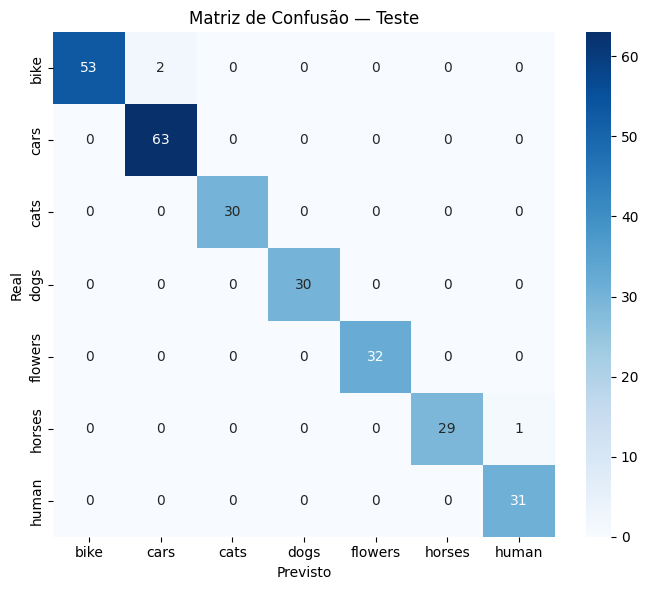

In [41]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print(classification_report(
    test_metrics["targets"],
    test_metrics["predictions"],
    target_names=CATEGORIES,
    zero_division=0
))

cm = confusion_matrix(test_metrics["targets"], test_metrics["predictions"])

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CATEGORIES, yticklabels=CATEGORIES)
plt.xlabel("Previsto")
plt.ylabel("Real")
plt.title("Matriz de Confusão — Teste")
plt.tight_layout()
plt.show()

In [42]:
per_class_total = cm.sum(axis=1)
per_class_accuracy = cm.diagonal() / per_class_total

for category, accuracy, total in zip(CATEGORIES, per_class_accuracy, per_class_total):
    print(f"{category:8s} accuracy: {accuracy:.4f}  ({int(round(accuracy * total))}/{int(total)})")

print(f"\n{'global':8s} accuracy: {test_metrics['accuracy']:.4f}  ({int(cm.trace())}/{int(cm.sum())})")

bike     accuracy: 0.9636  (53/55)
cars     accuracy: 1.0000  (63/63)
cats     accuracy: 1.0000  (30/30)
dogs     accuracy: 1.0000  (30/30)
flowers  accuracy: 1.0000  (32/32)
horses   accuracy: 0.9667  (29/30)
human    accuracy: 1.0000  (31/31)

global   accuracy: 0.9889  (268/271)


### Resultados no teste

Accuracy global de **98,89%** (268 de 271 imagens) e F1 macro de 0,9904. O valor é consistente com o da validação (98,52%), o que indica que a seleção do checkpoint pela Val Loss não superajustou o conjunto de validação.

| Classe | Accuracy (recall) | Precision | Suporte |
|---|---|---|---|
| bike | 0,9636 (53/55) | 1,00 | 55 |
| cars | 1,0000 (63/63) | 0,97 | 63 |
| cats | 1,0000 (30/30) | 1,00 | 30 |
| dogs | 1,0000 (30/30) | 1,00 | 30 |
| flowers | 1,0000 (32/32) | 1,00 | 32 |
| horses | 0,9667 (29/30) | 1,00 | 30 |
| human | 1,0000 (31/31) | 0,97 | 31 |

Erros no teste: 3


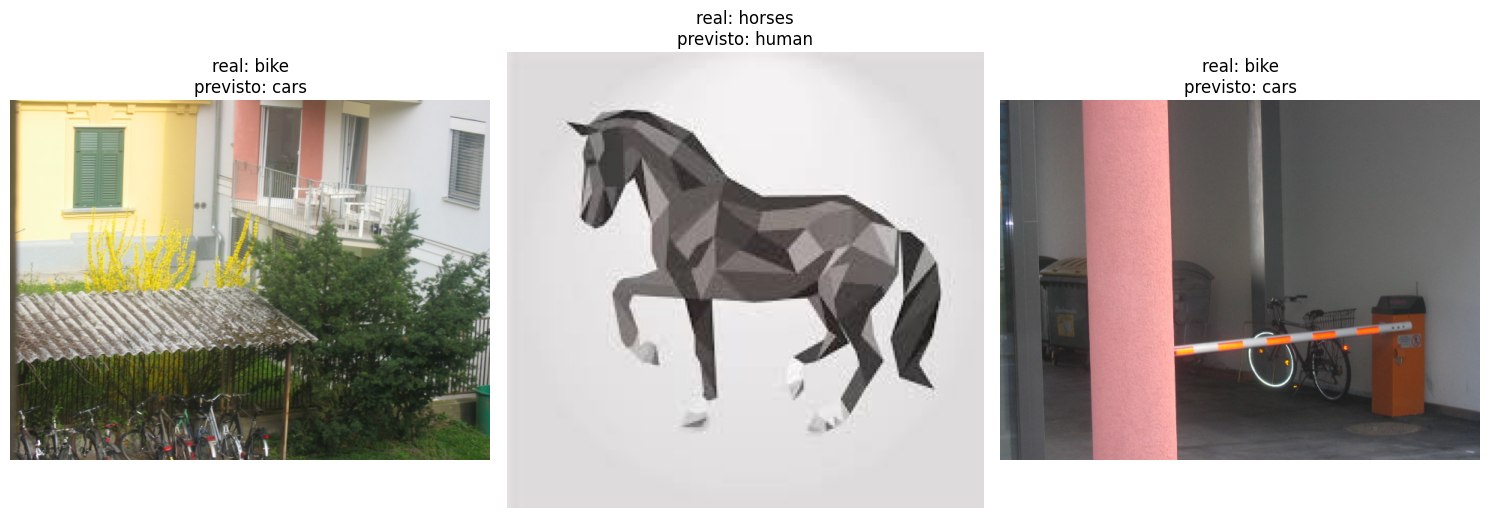

In [43]:
model.eval()
wrong = []

with torch.no_grad():
    for i in range(len(test_dataset)):
        image, label = test_dataset[i]
        pred = model(image.unsqueeze(0).to(device)).argmax(dim=1).item()
        if pred != label:
            wrong.append((i, label, pred))

print(f"Erros no teste: {len(wrong)}")

if wrong:
    fig, axes = plt.subplots(1, len(wrong), figsize=(5 * len(wrong), 5))
    if len(wrong) == 1:
        axes = [axes]
    for ax, (i, label, pred) in zip(axes, wrong):
        ax.imshow(Image.open(test_dataset.paths[i]).convert("RGB"))
        ax.set_title(f"real: {idx_to_label[label]}\nprevisto: {idx_to_label[pred]}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

### Análise dos erros

O modelo errou 3 das 271 imagens de teste, mostradas acima:

1. **bike → cars (pátio residencial):** as bicicletas aparecem pequenas, empilhadas e cortadas na borda inferior da foto, e a cena é dominada pela fachada de um prédio, por um telhado e por vegetação.
2. **horses → human (ilustração):** a imagem não é uma fotografia, e sim uma ilustração de cavalo em estilo *low-poly* (facetas geométricas em tons de cinza) sobre fundo claro.
3. **bike → cars (garagem):** a bicicleta é pequena e está parcialmente tapada por uma cancela de estacionamento, com um pilar grande em primeiro plano.

**Hipóteses (não verificadas com mapas de atenção ou Grad-CAM):** nos dois erros de bike, o objeto ocupa uma pequena parte da imagem e o contexto (pátio e garagem com cancela) costuma estar associado a carros. Como cars também é a maior classe do dataset (420 imagens, 23%), esse contexto pode ter pesado mais do que a bicicleta em si. No erro de horses, a imagem pertence a outro domínio visual (ilustração, sem as texturas de fotografia em que o backbone foi pré-treinado), o que pode ter degradado as features de "cavalo". Nos três casos, o erro parece vir de escala, oclusão e domínio visual, e não de semelhança entre as classes.

### Análise crítica

Com 3 erros em 271 imagens, o resultado está próximo do teto, e cada imagem vale 0,37 ponto percentual de accuracy global, então o conjunto de teste é pouco informativo para comparar melhorias pequenas. O dataset também é relativamente fácil para um backbone pré-treinado no ImageNet (classes genéricas e próximas de categorias do ImageNet), e o resultado não garante o mesmo desempenho em imagens com condições bem diferentes. Os três erros indicam onde estão os pontos fracos: objetos pequenos ou parcialmente ocultos em cenas dominadas por outro contexto, e imagens fora do domínio fotográfico. As propostas de augmentation da seção final foram escolhidas para atacar esses casos e aumentar a robustez, mais do que para ganhar accuracy neste conjunto de teste.

## Checkpoint e requirements.txt

In [44]:
checkpoint_path = f"{PROJECT_DIR}/checkpoints/resnet50_feature_extraction.pt"
os.makedirs(os.path.dirname(checkpoint_path), exist_ok=True)
torch.save(best_state, checkpoint_path)
print(f"Checkpoint salvo em: {checkpoint_path}")

Checkpoint salvo em: /content/drive/MyDrive/3_cnn/checkpoints/resnet50_feature_extraction.pt


In [45]:
requirements_content = (
    f"torch=={torch.__version__.split('+')[0]}\n"
    f"torchvision=={torchvision.__version__.split('+')[0]}\n"
    f"pandas=={pd.__version__}\n"
    f"numpy=={np.__version__}\n"
    f"scikit-learn=={sklearn.__version__}\n"
    "matplotlib\nseaborn\nPillow\n"
)

requirements_path = f"{PROJECT_DIR}/requirements.txt"

with open(requirements_path, "w") as f:
    f.write(requirements_content)

print(f"requirements.txt salvo em: {requirements_path}")
print()
print(requirements_content)

requirements.txt salvo em: /content/drive/MyDrive/3_cnn/requirements.txt

torch==2.11.0
torchvision==0.26.0
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
matplotlib
seaborn
Pillow



## Discussão: Feature Extraction vs. Fine-tuning

**Quando usar feature extraction (o que foi feito aqui):** quando o dataset-alvo é pequeno (aqui, 1.803 imagens, de 202 a 420 por classe) e o domínio é próximo do domínio de pré-treinamento. As nossas classes são, na maior parte, objetos e animais comuns, bem representados no ImageNet, então as features convolucionais já aprendidas são diretamente aproveitáveis. Treinar apenas a camada final reduz o risco de overfitting (só 0,06% dos parâmetros são atualizados) e, neste caso, bastou para chegar a 98,89% de accuracy no teste.

**Quando fine-tuning seria mais apropriado:** quando o domínio-alvo diverge do ImageNet (ex.: radiografias, como no Estudo de Caso 4.1 desta disciplina). Nesses casos, as features de baixo e médio nível aprendidas em fotos naturais podem não transferir bem, e descongelar as últimas camadas convolucionais (não necessariamente a rede inteira), com learning rate bem menor para o backbone do que para o novo head, permite reaprender representações específicas do novo domínio. O fine-tuning também se torna mais seguro e mais útil à medida que o dataset-alvo cresce, pois há exemplos suficientes para ajustar mais parâmetros sem memorizar o treino. Para este dataset, dado o tamanho pequeno, a proximidade com o ImageNet e o resultado já próximo do teto (3 erros em 271), o fine-tuning traria ganho marginal ao custo de maior risco de overfitting. Feature extraction é a escolha mais apropriada aqui.

## Discussão: Propostas de Augmentation e Riscos por Classe

**Geometric augmentation**

- *Flip horizontal:* benéfico para as 7 classes. Nenhuma tem orientação esquerda/direita semanticamente fixa (um cachorro, carro ou bicicleta virado para a esquerda é tão válido quanto para a direita).
- *Flip vertical:* **não recomendado para nenhuma classe.** Carros, bicicletas, cavalos, cães, gatos e pessoas de cabeça para baixo não ocorrem na distribuição real e introduziriam exemplos artificiais que atrapalham mais do que ajudam.
- *Rotação leve (±10-15°):* benéfica para a maioria das classes, pela robustez a fotos tiradas com leve inclinação de câmera. Rotações maiores (acima de ~30°) produzem cenas irreais (horizonte inclinado, carros tombados) e devem ser evitadas.
- *Recorte aleatório (random crop):* útil para robustez a enquadramento, mas com dois riscos específicos. Em "flowers", um corte pode remover a flor do quadro e sobrar só folhagem. Em "bike", onde o objeto costuma ser pequeno na cena (como nos dois erros observados no teste), um corte agressivo pode eliminar a bicicleta mantendo o rótulo, criando ruído de rótulo. Recomenda-se crop moderado (manter pelo menos 70-80% da área original).

**Color augmentation**

- *Color jitter (brilho, contraste, saturação):* genericamente benéfico, pois reduz a dependência de condições de iluminação específicas. O risco é baixo aqui porque cada classe é uma categoria ampla (não há subclasses distinguidas por cor), então variar a cor não cria confusão entre as 7 classes.
- *Conversão aleatória para grayscale:* **arriscada para "flowers"**, em que a cor é um dos sinais mais fortes para separar a flor da folhagem verde. Para as demais classes, formas e texturas dominam mais que a cor, e o risco é baixo. Recomenda-se baixa probabilidade (ex.: 10%). O erro de horses → human, em uma ilustração em tons de cinza, sugere que expor o modelo a imagens com pouca cor e aparência não fotográfica pode ajudar na robustez, mas isso é uma hipótese a testar.

**Scale variation**

- *Resize aleatório com crop (multi-scale training):* benéfico para todas as classes, pois os objetos aparecem em escalas diferentes (cavalo de perto vs. de longe). É a estratégia mais diretamente ligada aos erros observados: nos dois erros de bike, o objeto era pequeno na imagem, e treinar com variação de zoom aumenta o tamanho aparente de objetos pequenos. Vale a mesma ressalva do recorte, quanto a cortes que removem o objeto.

**Normalização**

Já tratada como obrigatória na seção de pré-processamento (média e desvio padrão do ImageNet). Não é uma melhoria opcional neste caso: é um requisito para o backbone pré-treinado funcionar corretamente desde a primeira época.

**Prioridade de teste:** começaríamos por flip horizontal, rotação leve, random resized crop com área mínima de 70-80% e color jitter moderado, e mediríamos o efeito sobre o recall da classe bike e sobre os três erros observados.